In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (
StandardScaler,
OneHotEncoder
)
from sklearn.metrics import (
accuracy_score,
f1_score,
precision_score,
log_loss
)

In [8]:
df = pd.read_csv("/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv")
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [9]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [10]:
 df.eq(0).sum()

Time           2
V1             0
V2             0
V3             0
V4             0
V5             0
V6             0
V7             0
V8             0
V9             0
V10            0
V11            0
V12            0
V13            0
V14            0
V15            0
V16            0
V17            0
V18            0
V19            0
V20            0
V21            0
V22            0
V23            0
V24            0
V25            0
V26            0
V27            0
V28            0
Amount      1825
Class     284315
dtype: int64

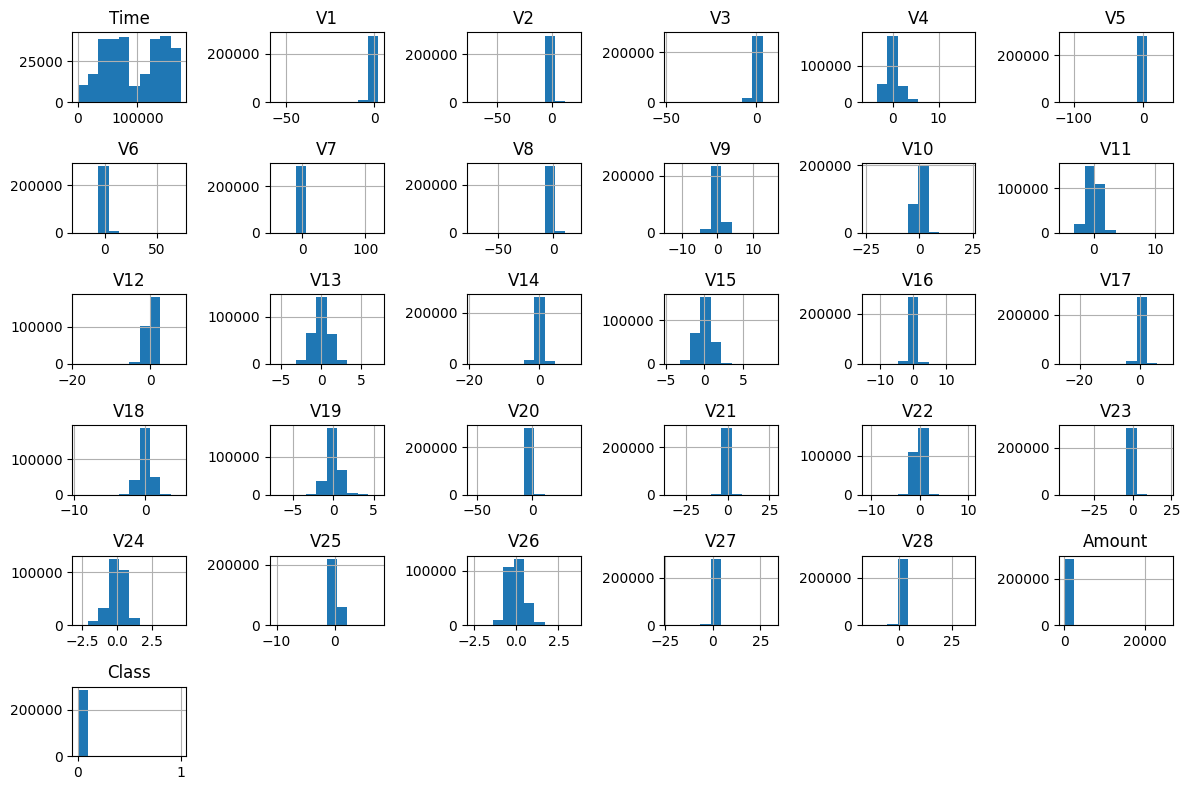

In [11]:
df.hist(figsize=(12, 8))
plt.tight_layout()
plt.show()

In [12]:
## checking for nulls

df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [13]:
## splitting data 80/20

X_train,X_test,Y_train,Y_test = train_test_split(df.drop(columns='Class'),df['Class'],train_size=0.8,random_state=42)

In [14]:
##scaling
Scaler = StandardScaler()

X_train = Scaler.fit_transform(X_train)
X_test = Scaler.transform(X_test)

In [68]:
class CustomLogisticRegression:
    def __init__(self,learning_rate=1e-1,epochs=6000):
        self.learning_rate = learning_rate
        self.epochs = epochs

    def fit(self, X, Y):
        X = np.asarray(X)
        Y = np.asarray(Y).reshape(-1,1)
        n_samples,n_features = X.shape

        
        self.W = np.zeros(n_features).reshape(-1,1)
        self.bias = 0
        self.loss_history = []

        
        for epoch in range(self.epochs):
            prediction = X @ self.W + self.bias           
            
            prediction = 1 / (1 + np.exp(-1 * prediction))      

            
            cost = Y * np.log(prediction) + (1 - Y) * np.log(1 - prediction)

            dw = X.T @ (Y - prediction) / n_samples
            db = np.mean(Y - prediction)

            self.W += self.learning_rate * dw
            self.bias += self.learning_rate * db

            loss = np.mean(-cost)

            self.loss_history.append(loss)
            print(f"Epoch = {epoch + 1}/{self.epochs}")
            print(f"Training Loss = {loss}")
            print()
            
    def predict(self, X):
        X = np.asarray(X)

        z = X @ self.W + self.bias
        
        return (1 / (1 + np.exp(-z)))
    

In [69]:
lr_custom = CustomLogisticRegression()

lr_sklearn = LogisticRegression()

In [70]:
lr_custom.fit(X_train,Y_train)
lr_sklearn.fit(X_train,Y_train)

Epoch = 1/6000
Training Loss = 0.6931471805599451

Epoch = 2/6000
Training Loss = 0.6685414658880671

Epoch = 3/6000
Training Loss = 0.6451500861805154

Epoch = 4/6000
Training Loss = 0.622911396329535

Epoch = 5/6000
Training Loss = 0.601765758700065

Epoch = 6/6000
Training Loss = 0.5816557066334113

Epoch = 7/6000
Training Loss = 0.5625260601554987

Epoch = 8/6000
Training Loss = 0.5443239999373074

Epoch = 9/6000
Training Loss = 0.526999105373059

Epoch = 10/6000
Training Loss = 0.5105033623169136

Epoch = 11/6000
Training Loss = 0.494791145599004

Epoch = 12/6000
Training Loss = 0.47981918096600695

Epoch = 13/6000
Training Loss = 0.4655464905914408

Epoch = 14/6000
Training Loss = 0.4519343258003259

Epoch = 15/6000
Training Loss = 0.4389460901691463

Epoch = 16/6000
Training Loss = 0.42654725570704705

Epoch = 17/6000
Training Loss = 0.4147052744053808

Epoch = 18/6000
Training Loss = 0.4033894870640267

Epoch = 19/6000
Training Loss = 0.3925710309657027

Epoch = 20/6000
Trainin

LogisticRegression()

In [71]:
predictions_custom = lr_custom.predict(X_test)
loss_custom = log_loss(Y_test, predictions_custom)

sklearn_test_probs = lr_sklearn.predict_proba(X_test)[:, 1]
sklearn_test_loss = log_loss(Y_test, sklearn_test_probs)

print(f"Custom LR test loss:   {loss_custom:.6f}")
print(f"Sklearn LR test loss:  {sklearn_test_loss:.6f}")

Custom LR test loss:   0.005365
Sklearn LR test loss:  0.004341


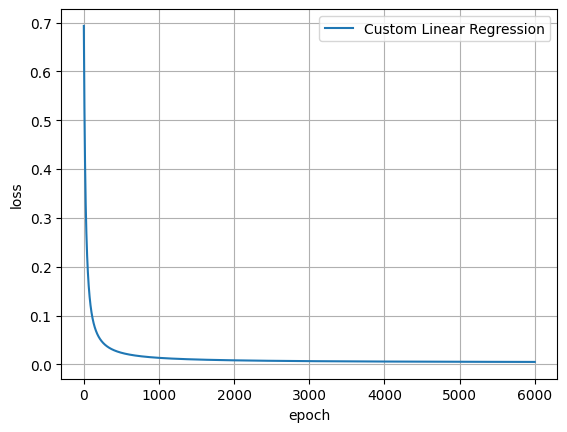

In [72]:
plt.plot(lr_custom.loss_history, label='Custom Linear Regression')

plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid()
plt.show()